In [1]:
import sys; sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib_inline
from sklearn.model_selection import train_test_split

In [3]:
import utils 
utils.style()

In [4]:
df = utils.load_saheart()
df.head()

,sbp,tobacco,ldl,adiposity,famhist,typea,obesity,alcohol,age,chd
row.names,,,,,,,,,,
1,160,12.00,5.73,23.11,1,49,25.30,97.20,52,1
2,144,0.01,4.41,28.61,0,55,28.87,2.06,63,1
3,118,0.08,3.48,32.28,1,52,29.14,3.81,46,0
4,170,7.50,6.41,38.03,1,51,31.99,24.26,58,1
5,134,13.60,3.50,27.78,1,60,25.99,57.34,49,1


In [5]:
df.shape

(462, 10)

donc il y a 462 individus et 9 variables.

In [6]:
# La proportion de chaque classe 
df["chd"].value_counts() / len(df)

chd
0    0.65368
1    0.34632
Name: count, dtype: float64

La classe 0 représente 65,37 % des observations (302/462), tandis que la classe 1 représente 34,63 % (160/462).

### Notification 
Il y a 2 type de classe 0 est normale et 1 est malade

In [7]:
len(df[df["chd"] == 1]) 

160

donc il y a 160 malades

In [8]:
len(df[df["chd"] == 0])

302

donc il y a 302 normals

##### A La proportion des malades par rappots des normales

In [9]:
len(df[df["chd"] == 1]) / len(df[df["chd"] == 0])   

0.5298013245033113

#### Quelle erreur ferait un classifieur qui repond toujours "sain"

Nghia la ta gia su ta gap 1 classifieur ma luc nao cung noi sain nghia la ta tinh ti le cua nguoi benh so voi tat ca observation

In [10]:
# Cach 1 
error = (df["chd"] == 1).mean()
print(error)

0.3463203463203463


In [11]:
# Cach 2
error = 160 / len(df)
print(error)

0.3463203463203463


----> Tại sao họ nói “référence” ?

Vì sau này ta tao các classifier khác. Ví dụ một model cho:

Erreur = 25% thì nó đã cải thiện so với classifier ngu ngơ luôn trả lời "sain" (34,63%).

Còn nếu model cho: Erreur = 40% thì nó còn tệ hơn baseline này.

#### C Calcule les effectifs par class et erreur du classifieur constant.

In [12]:
effectifs = df["chd"].value_counts()
print(effectifs)

chd
0    302
1    160
Name: count, dtype: int64


In [13]:
erreur_constante = len(df[df["chd"] == 1]) / len(df)
print(erreur_constante)

0.3463203463203463


## 2.2 1.2 Regarder les donnes

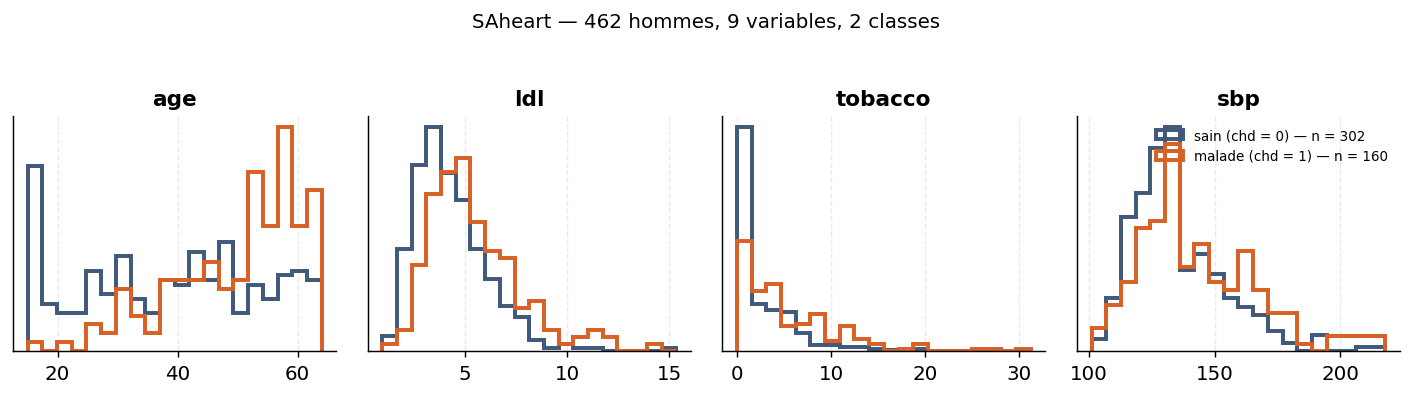

In [14]:
fig = utils.plot_saheart_apercu()

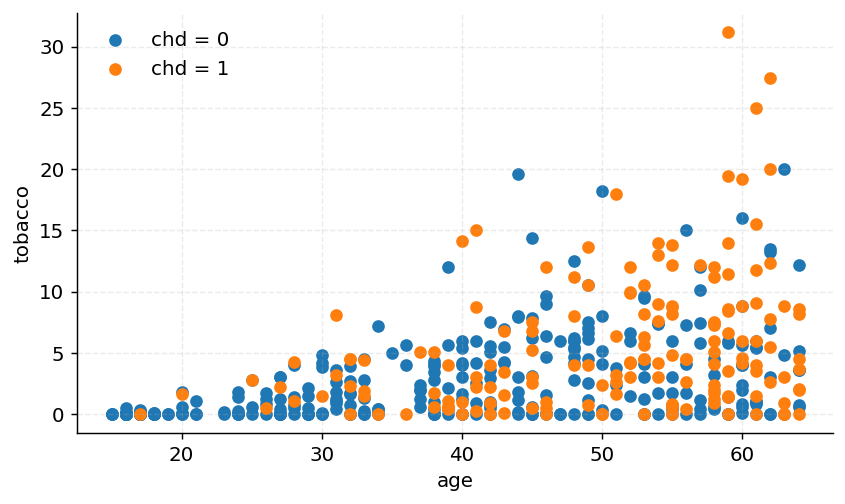

In [15]:
import matplotlib.pyplot as plt

plt.scatter(df[df["chd"] == 0]["age"],
            df[df["chd"] == 0]["tobacco"],
            label="chd = 0")

plt.scatter(df[df["chd"] == 1]["age"],
            df[df["chd"] == 1]["tobacco"],
            label="chd = 1")

plt.xlabel("age")
plt.ylabel("tobacco")
plt.legend()
plt.show()

#### 2.3 1.3 Decouper

In [23]:
# Sans stratify 
VARIABLES = [
    "sbp", "tobacco", "ldl", "adiposity",
    "typea", "obesity", "alcohol", "age"
]

X = df[VARIABLES].to_numpy()
y = df["chd"].to_numpy()

GRAINE = 42
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=GRAINE,
    #stratify=y
)

print("Sans stratify")
print("\n")
print("Moyenne Train :", y_train.mean())
print("Moyenne Test  :", y_test.mean())
print("\n")
print("Train:")
print(pd.Series(y_train).value_counts(normalize=True))
print("\n")
print("Test:")
print(pd.Series(y_test).value_counts(normalize=True))

Sans stratify


Moyenne Train : 0.34365325077399383
Moyenne Test  : 0.35251798561151076


Train:
0    0.656347
1    0.343653
Name: proportion, dtype: float64


Test:
0    0.647482
1    0.352518
Name: proportion, dtype: float64


In [24]:
VARIABLES = [
    "sbp", "tobacco", "ldl", "adiposity",
    "typea", "obesity", "alcohol", "age"
]

X = df[VARIABLES].to_numpy()
y = df["chd"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=GRAINE,
    stratify=y
)

print("Avec stratify")
print("\n")
print("Moyenne Train :", y_train.mean())
print("Moyenne Test  :", y_test.mean())
print("\n")
print("Train:")
print(pd.Series(y_train).value_counts(normalize=True))
print("\n")
print("Test:")
print(pd.Series(y_test).value_counts(normalize=True))

Avec stratify


Moyenne Train : 0.34674922600619196
Moyenne Test  : 0.34532374100719426


Train:
0    0.653251
1    0.346749
Name: proportion, dtype: float64


Test:
0    0.654676
1    0.345324
Name: proportion, dtype: float64


# 3 Exercice 2 — Bayes naïf, à la main

### 3.1 2.1 Ecrire la classe

In [45]:
class BayesNaifGaussien:
    """Classifieur de Bayes naïf gaussien, écrit à la main."""

    def fit(self, X, y):
        self.classes_ = np.unique(y)

        # Proportion de chaque classe
        self.pi_ = np.array([np.mean(y == k) for k in self.classes_])

        # Moyenne de chaque variable pour chaque classe
        self.mu_ = np.array([X[y == k].mean(axis=0) for k in self.classes_])

        # Écart-type de chaque variable pour chaque classe
        self.sigma_ = np.array([X[y == k].std(axis=0)for k in self.classes_])

        return self

    def _log_densite(self, X, k):
        """log f_k(x) pour chaque ligne de X, sous l'hypothèse naïve."""
        mu = self.mu_[k]
        sigma = self.sigma_[k]
        return np.sum(-0.5 * np.log(2 * np.pi) - np.log(sigma)- (X - mu) ** 2 / (2 * sigma ** 2), axis=1 )

    def predict(self, X):
        log_posterieurs = np.array([
            np.log(self.pi_[k]) + self._log_densite(X, k)
            for k in range(len(self.classes_)) ])

        indices = np.argmax(log_posterieurs, axis=0)

        return self.classes_[indices]

    def score(self, X, y):
            """Retourne l'accuracy du modèle."""
            y_pred = self.predict(X)
            return np.mean(y_pred == y)

### 3.2 2.2 Deux erreurs, pas une 

In [36]:
# Calcul de l'erreur de classification avec le classifieur Bayes Naïf Gaussien

bayes = BayesNaifGaussien()
bayes.fit(X_train, y_train)

# Prédictions
y_train_pred = bayes.predict(X_train)
y_test_pred = bayes.predict(X_test)

# Erreurs de classification
erreur_apprentissage = np.mean(y_train_pred != y_train)
erreur_test = np.mean(y_test_pred != y_test)

print(f"Erreur d'apprentissage : {erreur_apprentissage:.3f}")
print(f"Erreur de test         : {erreur_test:.3f}")
print("Erreur constante       :" ,round(error,3))


Erreur d'apprentissage : 0.282
Erreur de test         : 0.331
Erreur constante       : 0.346


Có thể thấy rằng đó là cái thấp nhất là lỗi appren và điều này thì có thể dự đoán được. Do mô hình Bayes đươc fit trên tập apprentisage chỗ bayes.fit(X_train, y_train) sau đó ta dùng X_train để dự đoán do đó mô hình được xây dựng dựa trên X_train nên nó sẽ mắc ít lỗi hơn. Trong khi đó, X_test là dữ liệu mà mô hình chưa thấy khi học nên lỗi test sẽ cao hơn. Nhưng nhìn chung thì cả 2 cho thấy rằng đều ít hơn là cái lỗi mà mô hình luôn chọn sai cho thấy là mô hình này hoạt động tương đối ổn định.

### 3.3 2.3 Se comparer à scikit-learn

In [39]:
# Ajustement du modèle scikit-learn

from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

# Prédictions
y_train_pred_gnb = gnb.predict(X_train)
y_test_pred_gnb = gnb.predict(X_test)

# print("Prédictions train identiques :", np.array_equal(y_train_pred, y_train_pred_gnb))
# print("Prédictions test identiques  :", np.array_equal(y_test_pred, y_test_pred_gnb))

print(f"Erreur train GaussianNB : {np.mean(y_train_pred_gnb != y_train):.3f}")
print(f"Erreur test GaussianNB  : {np.mean(y_test_pred_gnb != y_test):.3f}")

# Comparaison des paramètres
# print("\nMoyennes identiques :", np.allclose(bayes.mu_, gnb.theta_))
# print("Moyennes maximales différences :", np.max(np.abs(bayes.mu_ - gnb.theta_)))

# print("\nVariances identiques :", np.allclose(bayes.sigma_ ** 2, gnb.var_))
# print("Variances maximales différences :",
#     np.max(np.abs(bayes.sigma_ ** 2 - gnb.var_)))

# print("\nMoyennes personnalisées :")
# print(bayes.mu_)

# print("\nMoyennes GaussianNB :")
# print(gnb.theta_)

# print("\nVariances personnalisées :")
# print(bayes.sigma_ ** 2)

# print("\nVariances GaussianNB :")
# print(gnb.var_)

Erreur train GaussianNB : 0.282
Erreur test GaussianNB  : 0.331


In [40]:
print("Prédictions train identiques :", np.array_equal(y_train_pred, y_train_pred_gnb))
print("Prédictions test identiques  :", np.array_equal(y_test_pred, y_test_pred_gnb))

print(f"Erreur train GaussianNB : {np.mean(y_train_pred_gnb != y_train):.3f}")
print(f"Erreur test GaussianNB  : {np.mean(y_test_pred_gnb != y_test):.3f}")

#Comparaison des paramètres
print("\nMoyennes identiques :", np.allclose(bayes.mu_, gnb.theta_))
print("Moyennes maximales différences :", np.max(np.abs(bayes.mu_ - gnb.theta_)))

print("\nVariances identiques :", np.allclose(bayes.sigma_ ** 2, gnb.var_))
print("Variances maximales différences :",
    np.max(np.abs(bayes.sigma_ ** 2 - gnb.var_)))

print("\nMoyennes personnalisées :")
print(bayes.mu_)

print("\nMoyennes GaussianNB :")
print(gnb.theta_)

print("\nVariances personnalisées :")
print(bayes.sigma_ ** 2)

print("\nVariances GaussianNB :")
print(gnb.var_)

Prédictions train identiques : True
Prédictions test identiques  : True
Erreur train GaussianNB : 0.282
Erreur test GaussianNB  : 0.331

Moyennes identiques : True
Moyennes maximales différences : 0.0

Variances identiques : True
Variances maximales différences : 5.540730398934102e-07

Moyennes personnalisées :
[[135.67772512   2.6050237    4.25886256  23.96440758  52.08056872
   25.51957346  15.35876777  38.60189573]
 [143.20535714   4.98553571   5.61830357  27.80419643  54.29464286
   26.77758929  18.07080357  49.72321429]]

Moyennes GaussianNB :
[[135.67772512   2.6050237    4.25886256  23.96440758  52.08056872
   25.51957346  15.35876777  38.60189573]
 [143.20535714   4.98553571   5.61830357  27.80419643  54.29464286
   26.77758929  18.07080357  49.72321429]]

Variances personnalisées :
[[337.45064127  13.50434538   2.61931055  56.78836778  88.84184991
   13.54372541 501.28466199 217.85099167]
 [583.77032844  26.9707265    5.47179087  52.16287614 112.83282844
   20.50435222 648.717

# 4 Exercice 3 — LDA, QDA et frontières

### 4.1 3.1 Ajuster et comparer

#### LinearDiscriminantAnalysis

In [41]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Ajustement du modèle LDA
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)

# Prédictions
y_train_pred_lda = lda.predict(X_train)
y_test_pred_lda = lda.predict(X_test)

# Comparaison des erreurs
print(f"Erreur train LDA : {np.mean(y_train_pred_lda != y_train):.3f}")
print(f"Erreur test LDA  : {np.mean(y_test_pred_lda != y_test):.3f}")

Erreur train LDA : 0.266
Erreur test LDA  : 0.324


#### QuadraticDiscriminantAnalysis

In [42]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train, y_train)

# Predictions
y_train_pred_qda = qda.predict(X_train)
y_test_pred_qda = qda.predict(X_test)   

# Comparaison des erreurs
print(f"Erreur train QDA : {np.mean(y_train_pred_qda != y_train):.3f}")
print(f"Erreur test QDA  : {np.mean(y_test_pred_qda != y_test):.3f}")

Erreur train QDA : 0.251
Erreur test QDA  : 0.353


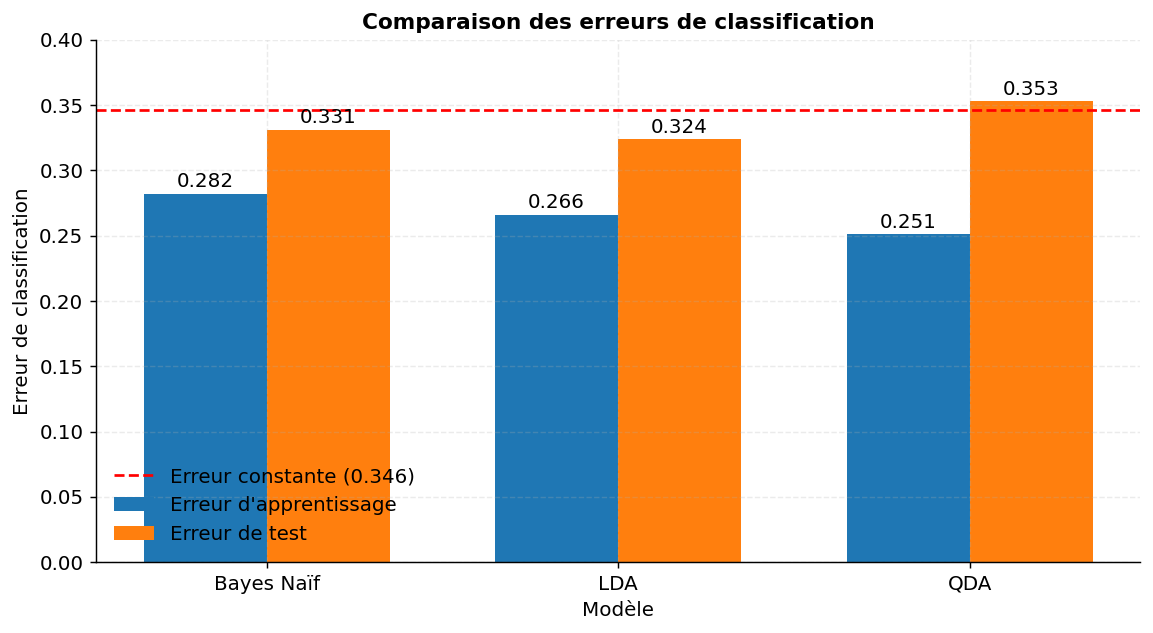

In [43]:
modeles = ["Bayes Naïf", "LDA", "QDA"]

erreur_train = [0.282, 0.266, 0.251]
erreur_test = [0.331, 0.324, 0.353]
erreur_constante = 0.346

x = np.arange(len(modeles))
largeur = 0.35

# Création de la figure
fig, ax = plt.subplots(figsize=(9, 5))

# Barres train et test
bar_train = ax.bar(x - largeur/2,erreur_train,largeur,label="Erreur d'apprentissage")

bar_test = ax.bar(x + largeur/2,erreur_test,largeur,label="Erreur de test")

# Ligne de référence : classifieur constant
ax.axhline(erreur_constante,color="red",linestyle="--",label="Erreur constante (0.346)")

# Valeurs au-dessus des barres
for bar in bar_train:
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.005,
        f"{bar.get_height():.3f}",
        ha="center"
    )

for bar in bar_test:
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.005,
        f"{bar.get_height():.3f}",
        ha="center"
    )

# Mise en forme
ax.set_ylabel("Erreur de classification")
ax.set_xlabel("Modèle")
ax.set_title("Comparaison des erreurs de classification")

ax.set_xticks(x)
ax.set_xticklabels(modeles)

ax.set_ylim(0, 0.40)

ax.legend()

plt.tight_layout()
plt.show()

### 4.2 3.2 Voir les frontières

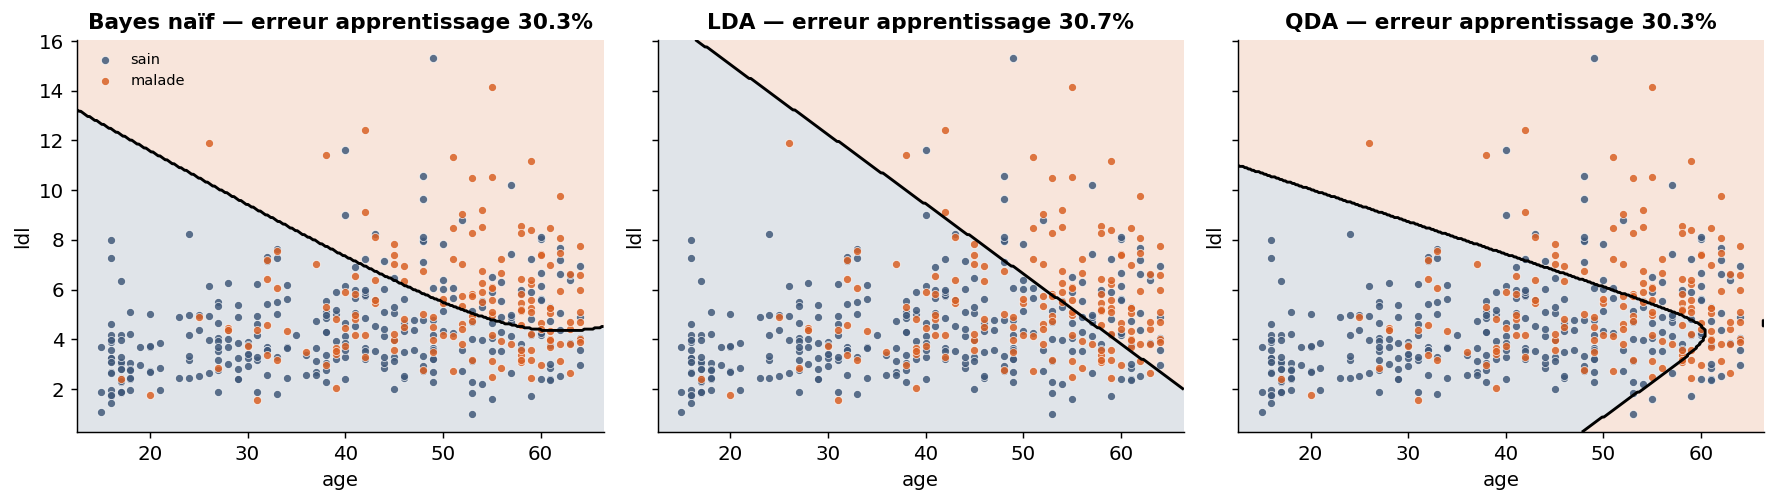

In [46]:
# Réajustement des trois modèles avec uniquement age et ldl
DEUX = ["age", "ldl"]
X2 = df[DEUX].to_numpy()

bayes_2 = BayesNaifGaussien().fit(X2, y)
lda_2 = LinearDiscriminantAnalysis().fit(X2, y)
qda_2 = QuadraticDiscriminantAnalysis().fit(X2, y)

modeles_2 = {
    "Bayes naïf": bayes_2,
    "LDA": lda_2,
    "QDA": qda_2,
}

fig = utils.comparer_frontieres(modeles_2, X2, y, noms=DEUX)

# 5 Exercice 4 — Évaluer autrement que par le taux d’erreur

### 5.1 4.1 Matrice de confusion

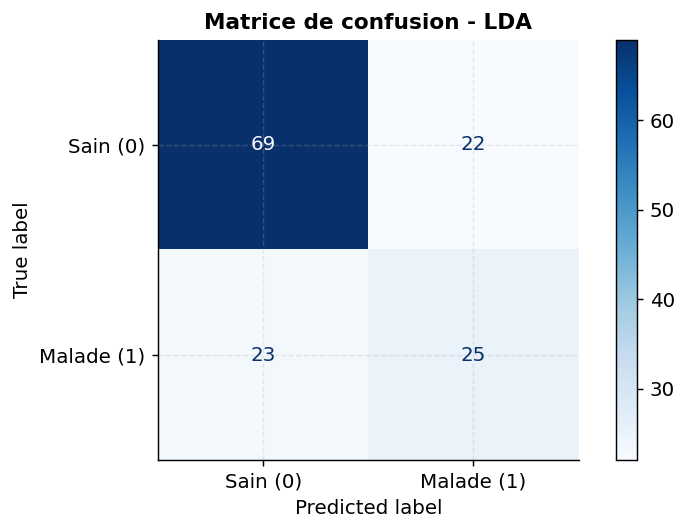

Précision : 0.532
Rappel    : 0.521
Sur 100 malades réels, le modèle en détecte environ 52.1.


In [47]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score
)

# Matrice de confusion sur l'échantillon de test
cm = confusion_matrix(y_test, y_test_pred_lda, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Sain (0)", "Malade (1)"]
)
disp.plot(cmap="Blues")
plt.title("Matrice de confusion - LDA")
plt.show()

# Précision et rappel pour la classe malade
precision = precision_score(y_test, y_test_pred_lda, pos_label=1)
rappel = recall_score(y_test, y_test_pred_lda, pos_label=1)

print(f"Précision : {precision:.3f}")
print(f"Rappel    : {rappel:.3f}")
print(f"Sur 100 malades réels, le modèle en détecte environ {100 * rappel:.1f}.")

## Giải thích Precision và Recall

### 1. Recall (Rappel)

**Recall** trả lời câu hỏi:

> Trong số những người **thực sự bị bệnh**, mô hình phát hiện được bao nhiêu người?

Công thức:

$$
Recall = \frac{VP}{VP + FN}
$$

Trong đó:

* **VP (True Positive / Vrai Positif)**: người thực sự bị bệnh và mô hình dự đoán là `malade`.
* **FN (False Negative / Faux Négatif)**: người thực sự bị bệnh nhưng mô hình dự đoán là `sain`.

Trong trường hợp này:

$$
Recall = 0.521 = 52.1\%
$$

Điều này có nghĩa là:

> **Trong 100 người thực sự bị bệnh, mô hình phát hiện được khoảng 52 người.**

Có thể hình dung như sau:

```text
100 người thực sự bị bệnh
│
├── 52 người → mô hình phát hiện là "malade" ✓
│
└── 48 người → mô hình dự đoán là "sain" ✗
```

Như vậy, mô hình **bỏ sót khoảng 47.9% số người thực sự bị bệnh**.

---

### 2. Precision (Précision)

**Precision** trả lời một câu hỏi khác:

> Trong số những người mà mô hình **dự đoán là bị bệnh**, thực sự có bao nhiêu người bị bệnh?

Công thức:

$$
Precision = \frac{VP}{VP + FP}
$$

Trong đó:

* **VP (True Positive / Vrai Positif)**: người thực sự bị bệnh và mô hình dự đoán là `malade`.
* **FP (False Positive / Faux Positif)**: người thực sự khỏe mạnh nhưng mô hình dự đoán là `malade`.

Trong trường hợp này:

$$
Precision = 0.532 = 53.2\%
$$

Điều này có nghĩa là:

> **Nếu mô hình dự đoán 100 người là "malade", thì khoảng 53 người thực sự bị bệnh.**

Khoảng 47 người còn lại là **False Positive**: mô hình dự đoán họ bị bệnh nhưng thực tế họ khỏe mạnh.

---

### 3. Sự khác nhau giữa Recall và Precision

Có thể nhớ đơn giản như sau:

**Recall:**

> Tôi có **100 người bệnh thật**, mô hình tìm được bao nhiêu người?

→ **52.1%**

**Precision:**

> Mô hình nói **100 người bị bệnh**, trong số đó có bao nhiêu người thực sự bị bệnh?

→ **53.2%**

| Chỉ số        | Câu hỏi                                                               |   Kết quả |
| ------------- | --------------------------------------------------------------------- | --------: |
| **Recall**    | Trong số người bệnh thật, mô hình phát hiện được bao nhiêu?           | **52.1%** |
| **Precision** | Trong số người được dự đoán là bệnh, có bao nhiêu người thực sự bệnh? | **53.2%** |

---

### 4. Liên hệ với Confusion Matrix

Ở đây ta quy ước:

* `1` = **malade** (bị bệnh)
* `0` = **sain** (khỏe mạnh)

Ma trận nhầm lẫn:

```text
                         Thực tế
                    Sain       Malade
                ┌──────────┬──────────┐
Dự đoán Sain    │    VN    │    FN    │
                ├──────────┼──────────┤
Dự đoán Malade  │    FP    │    VP    │
                └──────────┴──────────┘
```

Trong đó:

* **VN (True Negative)**: thực tế khỏe → mô hình dự đoán khỏe.
* **FP (False Positive)**: thực tế khỏe → mô hình dự đoán bệnh.
* **FN (False Negative)**: thực tế bệnh → mô hình dự đoán khỏe.
* **VP (True Positive)**: thực tế bệnh → mô hình dự đoán bệnh.

### Recall

Recall tập trung vào **những người thực sự bị bệnh**:

$$
Recall = \frac{VP}{VP + FN}
$$

### Precision

Precision tập trung vào **những người mà mô hình dự đoán là bị bệnh**:

$$
Precision = \frac{VP}{VP + FP}
$$

Vì vậy, mặc dù hai giá trị trong trường hợp này khá gần nhau (`52.1%` và `53.2%`), **Recall và Precision đo hai khía cạnh khác nhau của mô hình**.


### 5.2 4.2 Le coût n’est pas symétrique